In [10]:
import glob
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
DATA_DIR = Path("../data")
YOLO_DIR = DATA_DIR / "yolo_dataset"


In [ ]:

train_images_Glioma = glob.glob('../data/Train/Glioma/images/*.jpg')
train_images_Meningioma = glob.glob('../data/Train/Meningioma/images/*.jpg')
train_images_No_Tumor = glob.glob('../data/Train/No_Tumor/images/*.jpg')
train_images_Pituitary = glob.glob('../data/Train/Pituitary/images/*.jpg')

train_labels_Glioma = glob.glob('../data/Train/Glioma/labels/*.txt')
train_labels_Meningioma = glob.glob('../data/Train/Meningioma/labels/*.txt')
train_labels_No_Tumor = glob.glob('../data/Train/No_Tumor/labels/*.txt')
train_labels_Pituitary = glob.glob('../data/Train/Pituitary/labels/*.txt')

val_images_Glioma = glob.glob('../data/Val/Glioma/images/*.jpg')
val_images_Meningioma = glob.glob('../data/Val/Meningioma/images/*.jpg')
val_images_No_Tumor = glob.glob('../data/Val/No_Tumor/images/*.jpg')
val_images_Pituitary = glob.glob('../data/Val/Pituitary/images/*.jpg')

val_labels_Glioma = glob.glob('../data/Val/Glioma/labels/*.txt')
val_labels_Meningioma = glob.glob('../data/Val/Meningioma/labels/*.txt')
val_labels_No_Tumor = glob.glob('../data/Val/No_Tumor/labels/*.txt')
val_labels_Pituitary = glob.glob('../data/Val/Pituitary/labels/*.txt')

In [ ]:
# check files and pairs arr used to copy files and split data

classes = ["Glioma", "Meningioma", "Pituitary"]
pairs = []

for cls in classes:
    images = DATA_DIR / "Train" / cls / "images"
    labels = DATA_DIR / "Train" / cls / "labels"
    for img in images.glob("*.jpg"):
        label = labels / f"{img.stem}.txt"
        if label.exists():
            pairs.append((img, label, cls))
        else:
            print(f"Missing label: {img.name}")

train_pairs, test_pairs = train_test_split(pairs,test_size=0.2,random_state=100,stratify=[cls for _, _, cls in pairs])

print("Train:", len(train_pairs))
print("Test:", len(test_pairs))

Train: 3220
Test: 806


In [ ]:
import shutil

YOLO_DIR = DATA_DIR / "yolo_dataset"

for split in ["train", "val", "test"]:
    (YOLO_DIR / "images" / split).mkdir(parents=True, exist_ok=True)
    (YOLO_DIR / "labels" / split).mkdir(parents=True, exist_ok=True)


def copy_pairs(pairs, split):
    for img, label, cls in pairs:
        new_name = f"{cls}_{img.name}"

        shutil.copy2(img, YOLO_DIR / "images" / split / new_name)
        shutil.copy2(
            label,
            YOLO_DIR / "labels" / split / f"{Path(new_name).stem}.txt"
        )


copy_pairs(train_pairs, "train")
copy_pairs(test_pairs, "test")

# Copy existing validation data, excluding No_Tumor
val_pairs = []

for cls in classes:
    images = DATA_DIR / "Val" / cls / "images"
    labels = DATA_DIR / "Val" / cls / "labels"

    for img in images.glob("*.jpg"):
        label = labels / f"{img.stem}.txt"
        if label.exists():
            val_pairs.append((img, label, cls))

copy_pairs(val_pairs, "val")

print("YOLO dataset created:", YOLO_DIR)
print("Validation:", len(val_pairs))

YOLO dataset created: ..\data\yolo_dataset
Validation: 412


In [6]:
from collections import Counter

for split in ["train", "val", "test"]:
    counts = Counter()

    for label in (YOLO_DIR / "labels" / split).glob("*.txt"):
        for line in label.read_text().splitlines():
            if line.strip():
                counts[int(line.split()[0])] += 1

    print(split, counts)

train Counter({2: 1423, 1: 1186, 0: 1072})
val Counter({2: 161, 0: 153, 1: 142})
test Counter({2: 352, 1: 296, 0: 277})


In [33]:
for split in ["train", "val", "test"]:
    for label in (YOLO_DIR / "labels" / split).glob("*.txt"):
        lines = label.read_text().splitlines()
        updated_lines = []

        for line in lines:
            parts = line.split()
            if parts and parts[0] == "3":
                parts[0] = "2"
            updated_lines.append(" ".join(parts))

        label.write_text("\n".join(updated_lines) + "\n")

print("Class IDs remapped.")

Class IDs remapped.


In [ ]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

results = model.train(
    data=str(YOLO_DIR / "data.yaml"),
    epochs=50,
    imgsz=640,
    batch=8,
    patience=10,
    project="../runs/detect",
    name="mri_yolov8n" ,
    device=0
)

In [5]:
best_model = YOLO("../models/yolo_best.pt")

In [ ]:
test_metrics = best_model.val(
    data=str(YOLO_DIR / "data.yaml"),
    split="test",
)
metrics = best_model.val(
    data=str(YOLO_DIR / "data.yaml"),
    split="val"
)


In [48]:

print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

print("=" * 30)

print("Precision:", test_metrics.box.mp)
print("Recall:", test_metrics.box.mr)
print("mAP50:", test_metrics.box.map50)
print("mAP50-95:", test_metrics.box.map)

Precision: 0.9512878145781647
Recall: 0.9138500224880618
mAP50: 0.9510085691247626
mAP50-95: 0.7638588174261185
Precision: 0.9305003186948637
Recall: 0.9022330341943828
mAP50: 0.951947606552518
mAP50-95: 0.7506153267625314



image 1/1 c:\Users\ouich\Desktop\youcode\youcode_02_05\notebooks\..\data\yolo_dataset\images\test\Meningioma_m3 (57).jpg: 640x640 1 Meningioma, 28.5ms
Speed: 2.0ms preprocess, 28.5ms inference, 1.0ms postprocess per image at shape (1, 3, 640, 640)
Results saved to C:\Users\ouich\Desktop\youcode\youcode_02_05\notebooks\runs\detect\predict


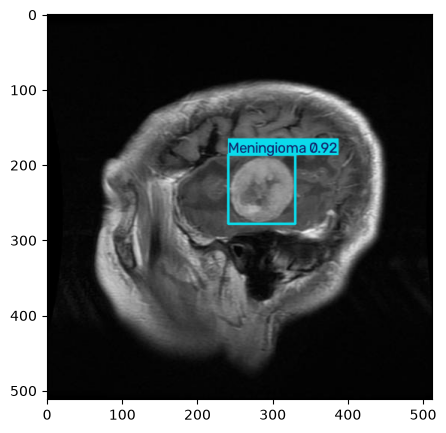

In [45]:
import random

test_images = list((YOLO_DIR / "images" / "test").glob("*.jpg"))

image_path = random.choice(test_images)

results = best_model.predict(
    source=str(image_path),
    conf=0.25,
    save=True
)

img = results[0].plot()
img = img[:,:,::-1]
plt.figure(figsize=(5 , 5))
plt.imshow(img)



In [ ]:
result = results[0]

for box in result.boxes:
    print("Class:", best_model.names[int(box.cls[0])])
    print("Confidence:", float(box.conf[0]))
    print("Coordinates:", box.xyxy[0].tolist())
    print("-" * 30)

print("-" * 30)



Class: Meningioma
Confidence: 0.9245897531509399
Coordinates: [241.625732421875, 186.93113708496094, 330.86126708984375, 278.0810546875]
------------------------------
------------------------------
Ultralytics 8.4.190  Python-3.14.7 torch-2.14.1+cpu CPU (Intel Core Ultra 7 165H)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
WARNING val: Slow image access detected (ping: 0.0±0.0 ms, read: 21.4±41.4 MB/s, size: 23.9 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning C:\Users\ouich\Desktop\youcode\youcode_02_05\data\yolo_dataset\labels\test... 806 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 806/806 638.0it/s 1.3s0.0s
val: New cache created: C:\Users\ouich\Desktop\youcode\youcode_02_05\data\yolo_dataset\labels\test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 51/51 1.3it/s 40.8

In [ ]:
test_metrics = best_model.val(
    data=str(YOLO_DIR / "data.yaml"),
    split="test"
)

print("Precision:", test_metrics.box.mp)
print("Recall:", test_metrics.box.mr)
print("mAP50:", test_metrics.box.map50)
print("mAP50-95:", test_metrics.box.map)